<h1>Cek Dataset</h1>

Mengimport Library

In [1]:
import pandas as pd
import numpy as np
from scipy import stats

Membaca dataset

In [2]:
df = pd.read_csv("Dataset_googleplaystore.csv")

print("INFORMASI DATASET: ")
df.info()

INFORMASI DATASET: 
<class 'pandas.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  str    
 1   Category        10841 non-null  str    
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  str    
 4   Size            10841 non-null  str    
 5   Installs        10841 non-null  str    
 6   Type            10840 non-null  str    
 7   Price           10841 non-null  str    
 8   Content Rating  10840 non-null  str    
 9   Genres          10841 non-null  str    
 10  Last Updated    10841 non-null  str    
 11  Current Ver     10833 non-null  str    
 12  Android Ver     10838 non-null  str    
dtypes: float64(1), str(12)
memory usage: 1.1 MB


Hitung nilai di kolom Type

In [3]:
df["Type"].value_counts(dropna=False)

Type
Free    10039
Paid      800
NaN         1
0           1
Name: count, dtype: int64

Informasi statistik kolom Rating

In [4]:
df["Rating"].describe()

count    9367.000000
mean        4.193338
std         0.537431
min         1.000000
25%         4.000000
50%         4.300000
75%         4.500000
max        19.000000
Name: Rating, dtype: float64

<h1>Data Cleaning</h1>

catatan untuk proses data cleaning

In [ ]:
log = []
log.clear()
log.append(("Data Awal", len(df)))

[('Data Awal', 10841)]


In [6]:
df_copy = df.copy()

Hapus baris yang nilai Type-nya tidak valid

In [ ]:
df = df[df["Type"].isin(["Free", "Paid"])]
log.append(("Data yang 'Type' nya selain Free dan Paid", len(df)))

Hapus Rating yang tidak valid

In [ ]:
df = df.dropna(subset=["Rating"])
df = df[df["Rating"].between(1, 5)]
log.append(("Data tanpa Rating tidak valid", len(df)))

Menghapus data duplikat

In [9]:
df = df.drop_duplicates(subset="App")
log.append(("Data tanpa aplikasi duplikat: ", len(df)))

In [10]:
for x in log:
    print(x)

('Data Awal', 10841)
("Menghapus baris yang 'Type' nya diluar Free dan Paid", 10839)
('Menghapus baris dengan Rating tidak valid', 9366)
('Data tanpa aplikasi duplikat: ', 8196)


<h3>Analisis Data</h3>
Ringkasan data perkelompok

In [11]:
ringkasan = df.groupby("Type")["Rating"].agg(["count", "mean", "std"])
ringkasan

,count,mean,std
Type,,,
Free,7592,4.166372,0.534163
Paid,604,4.259603,0.559961


*Simpan clean data*

In [12]:
df[["App", "Type", "Rating"]].to_csv("data_bersih.csv", index=False)

<h1>Hipotesis dan Alat Uji</h1>

Histogram

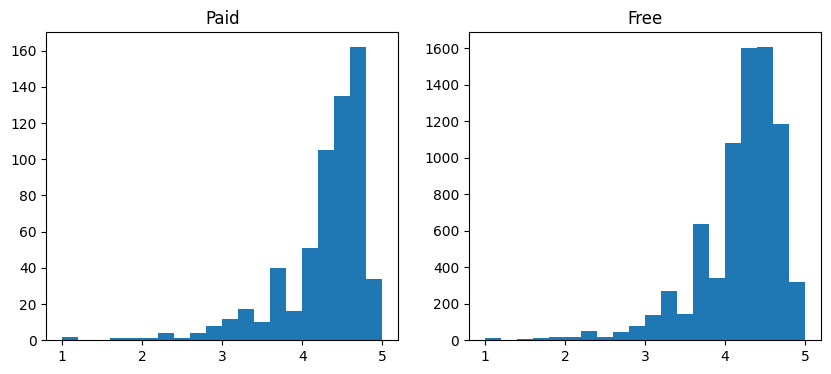

In [13]:
import matplotlib.pyplot as plt

paid = df[df["Type"] == "Paid"]["Rating"]
free = df[df["Type"] == "Free"]["Rating"]

fig, ax = plt.subplots(1, 2, figsize=(10, 4), sharey=False)
ax[0].hist(paid, bins=20); ax[0].set_title("Paid")
ax[1].hist(free, bins=20); ax[1].set_title("Free")
plt.show()

<h3>Skewness (kemiringan)</h3>

In [14]:
print("Skewness Paid:", stats.skew(paid))
print("Skewness Free:", stats.skew(free))

Skewness Paid: -1.9386202756031696
Skewness Free: -1.7353525481402197


<h3>Levene</h3>
H₀ Levene adalah "varians sama". Kalau p-value-nya kecil (< 0,05), varians berbeda dan Welch wajib. Kalau p-value-nya besar, varians boleh dianggap sama, tapi Welch tetap valid dan aman. Pikirkan apa yang akan kamu tulis untuk hasil milikmu, karena alasan memilih Welch harus bisa kamu jelaskan di laporan, termasuk kalau Levene tidak menolak H₀.

In [15]:
levene = stats.levene(paid, free)
print("Statistik Levene:", levene.statistic)
print("p-value:", levene.pvalue)

Statistik Levene: 0.20897243607694335
p-value: 0.6475861116367254


<h3>Uji-t Welch</h3>

In [16]:
hasil = stats.ttest_ind(paid, free, equal_var=False)

print("t        :", hasil.statistic)
print("df       :", hasil.df)
print("p-value  :", hasil.pvalue)

t        : 3.951297123068955
df       : 693.1812766988887
p-value  : 8.569040323075348e-05


<h3>Interval Kepercayaan 95%</h3>

In [17]:
ci = hasil.confidence_interval(confidence_level=0.95)
print("CI 95%:", ci.low, "sampai", ci.high)

CI 95%: 0.046904263386231826 sampai 0.13955603989571735


<h3>Ukuran efek (Cohen's d)</h3>

In [18]:
n1, n2 = len(paid), len(free)
s1, s2 = paid.std(), free.std()
sp = np.sqrt(((n1-1)*s1**2 + (n2-1)*s2**2) / (n1+n2-2))
d = (paid.mean() - free.mean()) / sp
print("Cohen's d:", d)

Cohen's d: 0.173903028008291


<h3>Keputusan</h3>

In [19]:
alpha = 0.05
if hasil.pvalue < alpha:
    print("Tolak H0")
else:
    print("Gagal tolak H0")

Tolak H0
